# Lab 7 – go-to-goal: model vs real trajectory

Odometry of the "54" trajectory, logged by the same program in the TRIK Studio simulator and on the real robot.

Log format: one line per sample, no header, `x,y,time` (x, y in m, time in ms).

- `odometry_gtg_sim.txt` – simulator
- `odometry_gtg_real.txt` – real robot

In [ ]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select both txt files

Saving odometry_gtg_real.txt to odometry_gtg_real (1).txt
Saving odometry_gtg_sim.txt to odometry_gtg_sim (1).txt


In [ ]:
x_s, y_s, t_s = np.loadtxt('odometry_gtg_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_gtg_real.txt', delimiter=',', unpack=True)

## 1. Trajectories on one plot

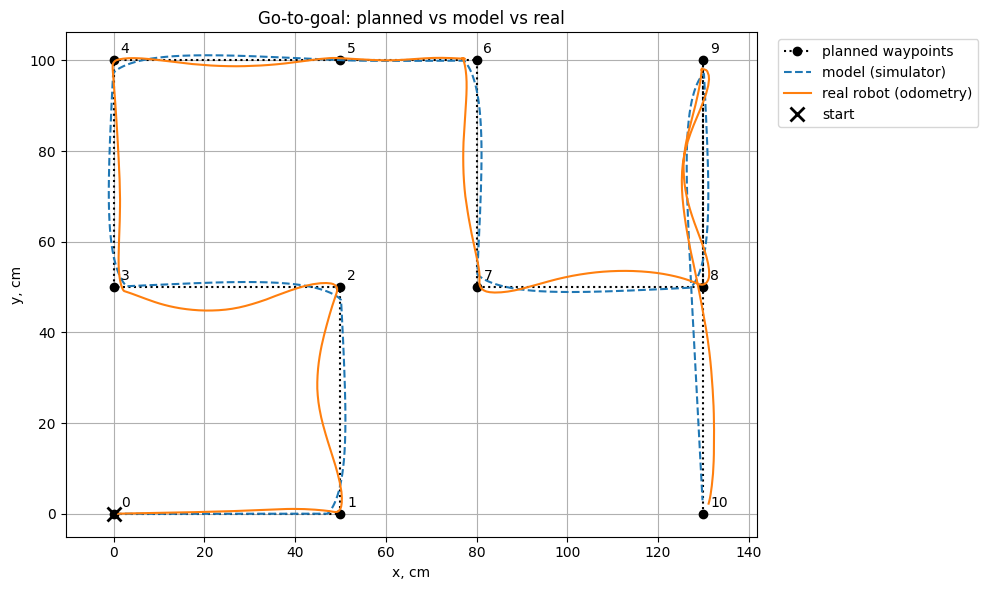

In [ ]:
# Planned waypoints in cm
wp = np.array([[0, 0],
               [50, 0], [50, 50], [0, 50], [0, 100], [50, 100],    # digit 5
               [80, 100],                                          # gap
               [80, 50], [130, 50], [130, 100], [130, 0]])         # digit 4

plt.figure(figsize=(10, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'kx', markersize=10, mew=2, label='start')
for i, (px, py) in enumerate(wp):                          # waypoint numbers, as in the miss table
    plt.annotate(str(i), (px, py), textcoords='offset points', xytext=(5, 5))
plt.axis('equal'); plt.grid(True)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))   # outside, so it doesn't cover waypoint 10
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Go-to-goal: planned vs model vs real')
plt.tight_layout()
plt.show()

## 2. Error over time

The simulator log is resampled onto the real-robot timestamps.

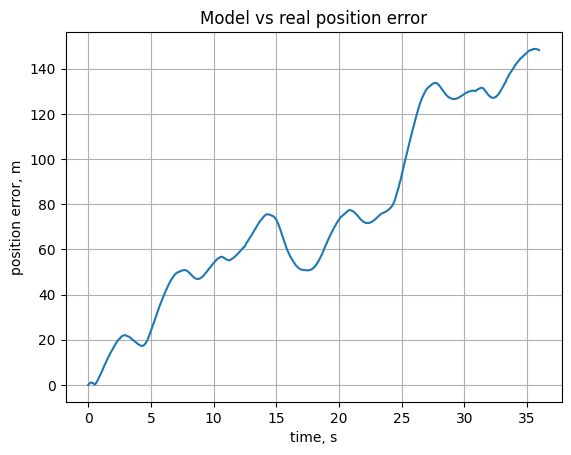

Final odometry error (sim vs real): 148.266 m
Max error: 148.789 m


In [ ]:
t_s, t_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.3f} m')
print(f'Max error: {err.max():.3f} m')

## 4. Discussion

The acceptance radius is 3 cm: the program switches to the next waypoint as soon as the robot is within 3 cm of the current one. So the simulated robot turns 3 cm before each corner; the only waypoint it passes exactly is (50, 100), where there is no turn. The real robot comes closer (0.3–2.5 cm), but not because it is more accurate. Its control loop runs every ~80 ms instead of 10 ms and it drives faster, so it moves up to ~3 cm between checks, notices it is inside the 3 cm circle late, and keeps rolling while it starts the turn. After each turn the real robot overshoots the new heading (up to 5 cm off the line, at (20, 45) after the (50, 50) corner). Go-to-goal then steers straight at the next waypoint rather than back to the line, so the robot only rejoins the line at the waypoint. This is a control problem: K_θ = 35 is too high for an ~80 ms loop with motor lag, and a lower gain, a derivative term or a faster loop would reduce it.
